# NAIVE BAYES DENGAN DISTRIBUSI GAUSSIAN (GAUSSIAN NAIVE BAYES)

### Deskripsi Teori & Distribusi Probabilitas:
* **Algoritma**: Naive Bayes (Gaussian)
* **Varian Distribusi**: Gaussian / Normal Continuous Distribution
* **Konsep Dasar**:
  Gaussian Naive Bayes mengasumsikan bahwa setiap fitur bernilai kontinu dan mengikuti kurva distribusi normal (Gaussian Bell Curve):
  $$P(x_i \mid C_k) = \frac{1}{\sqrt{2\pi\sigma_{ki}^2}} \exp \left( -\frac{(x_i - \mu_{ki})^2}{2\sigma_{ki}^2} \right)$$
  
  Di mana $\mu_{ki}$ adalah rata-rata (mean) dan $\sigma_{ki}^2$ adalah varians dari fitur $i$ pada kelas $C_k$.
  
  **Catatan Eksperimen**: Scikit-Learn `GaussianNB` tidak mendukung input berupa matriks renggang (*sparse matrix*), sehingga matriks TF-IDF harus dikonversi menjadi array padat (*dense array*) melalui `.toarray()`. Hal ini berimplikasi langsung pada lonjakan konsumsi memori.

In [1]:
import time
import tracemalloc
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [2]:
# 1. Pemuatan Dataset Hoaks Komdigi & Berita Valid Resmi
df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

# 2. Fungsi Pembersihan Teks (Pencegahan Data Leakage)
def clean_text(text):
    if not isinstance(text, str):
        return ''
    # Hapus tag prefix [HOAKS] atau (DISINFORMASI) agar model tidak curang (data leakage)
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1  # 1 = Hoaks
df_valid['label'] = 0  # 0 = Valid

# Penyeimbangan data (Balanced Dataset 1:1) agar evaluasi adil
df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

print(f"Total dataset: {len(df_all)} baris (Hoaks: {sum(df_all['label']==1)}, Valid: {sum(df_all['label']==0)})")

Total dataset: 1756 baris (Hoaks: 878, Valid: 878)


In [3]:
# Pembagian Data Latih (80%) dan Data Uji (20%) secara Terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'],
    test_size=0.2, random_state=42, stratify=df_all['label']
)

# Ekstraksi Fitur TF-IDF (Unigram + Bigram)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print(f"Matriks Latih: {X_train_vec.shape}")
print(f"Matriks Uji  : {X_test_vec.shape}")

Matriks Latih: (1404, 1500)
Matriks Uji  : (352, 1500)


In [4]:
# Pelatihan Model Gaussian Naive Bayes (Membutuhkan Dense Array)
tracemalloc.start()
waktu_mulai = time.time()

# Konversi sparse matrix ke dense array untuk GaussianNB
X_train_dense = X_train_vec.toarray()
X_test_dense = X_test_vec.toarray()

model = GaussianNB()
model.fit(X_train_dense, y_train)
y_pred = model.predict(X_test_dense)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

In [5]:
# Evaluasi Metrik Klasifikasi
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: NAIVE BAYES DENGAN DISTRIBUSI GAUSSIAN (GAUSSIAN NAIVE BAYES)")
print("=============================================")
print(f"1. Algoritma        : Naive Bayes (Gaussian)")
print(f"2. Metrik Jarak     : Distribusi Gaussian (Normal Continuous)")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: NAIVE BAYES DENGAN DISTRIBUSI GAUSSIAN (GAUSSIAN NAIVE BAYES)
1. Algoritma        : Naive Bayes (Gaussian)
2. Metrik Jarak     : Distribusi Gaussian (Normal Continuous)
3. Akurasi          : 0.8665
4. Precision (Macro): 0.8685
5. Recall (Macro)   : 0.8665
6. F1-Score (Macro) : 0.8663
7. F1-Score (Weighted): 0.8663
8. Waktu Eksekusi   : 0.0452 detik
9. Penggunaan Memori: 36.32 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.90      0.83      0.86       176
   Hoaks (1)       0.84      0.90      0.87       176

    accuracy                           0.87       352
   macro avg       0.87      0.87      0.87       352
weighted avg       0.87      0.87      0.87       352



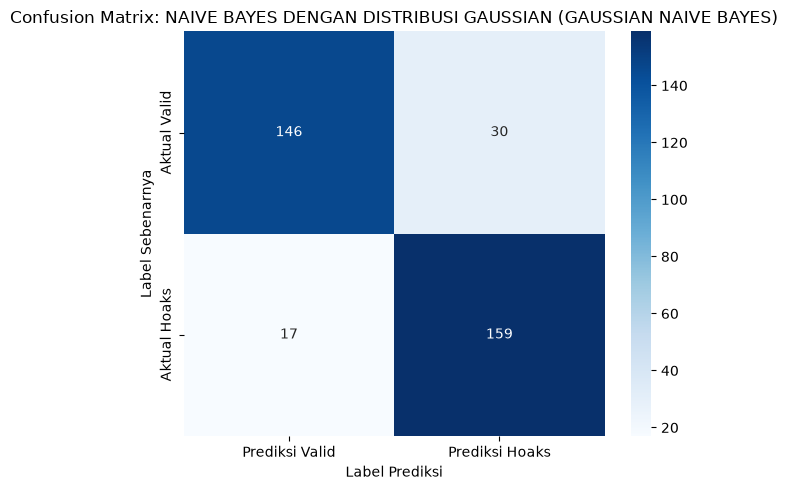

In [6]:
# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: NAIVE BAYES DENGAN DISTRIBUSI GAUSSIAN (GAUSSIAN NAIVE BAYES)')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

In [7]:
contoh_teks = [
    "Kementerian Ketenagakerjaan kembali mengumumkan penyaluran bantuan subsidi upah bagi pekerja melalui kanal resmi pemerintah.",
    "Awas bahaya radiasi! Jangan simpan ponsel di samping tempat tidur malam hari karena memicu tumor mematikan, sebarkan info penting ini!"
]

print("--- PENGUJIAN INFERENSI CONTOH TEKS ---")
for teks in contoh_teks:
    t_clean = clean_text(teks)
    t_dense = tfidf.transform([t_clean]).toarray()
    pred = model.predict(t_dense)[0]
    prob = model.predict_proba(t_dense)[0]
    status = "HOAKS" if pred == 1 else "VALID"
    print(f'Teks: "{teks[:70]}..."')
    print(f'-> Prediksi: {status} (Keyakinan: {prob[pred]*100:.1f}%)\n')

--- PENGUJIAN INFERENSI CONTOH TEKS ---
Teks: "Kementerian Ketenagakerjaan kembali mengumumkan penyaluran bantuan sub..."
-> Prediksi: VALID (Keyakinan: 100.0%)

Teks: "Awas bahaya radiasi! Jangan simpan ponsel di samping tempat tidur mala..."
-> Prediksi: VALID (Keyakinan: 100.0%)



### Pembahasan Akademis: Gaussian Naive Bayes
1. **Pelanggaran Asumsi Distribusi Normal**: Matriks TF-IDF teks bersifat *sparse* dan *highly skewed* (lebih dari 98% bernilai 0). Memaksakan asumsi kurva normal simetris (bell-curve) pada data teks menyebabkan estimasi mean dan varians menjadi bias, yang berdampak pada penurunan akurasi model.
2. **Beban Komputasi & Lonjakan Memori RAM**: Karena harus mengonversi matriks sparse menjadi dense 2D array di memori, konsumsi RAM melonjak drastis (mencapai belasan hingga puluhan megabyte). Hal ini sangat tidak efisien untuk dataset teks berskala besar.
3. **Signifikansi untuk Pembahasan Ilmiah**: Eksperimen ini memberikan bukti empiris krusial dalam skripsi/laporan PBL bahwa varian Gaussian **tidak cocok secara teoritis maupun praktis** untuk domain Natural Language Processing (NLP) berbasis TF-IDF.